# Space Mission Analytics Dashboard: Global Launch Trends & Mission Success

Question: How has the global space launch industry changed from 1957–2022, and what factors are associated with successful missions?

# 1. Import And Inspect Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

pd.set_option('display.max_columns', None)

In [6]:
from google.colab import files

uploaded = files.upload()
df = pd.read_csv('space_missions.csv', encoding='latin1')
df.head()

Saving space_missions.csv to space_missions (2).csv


,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus
0,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,NaN,Success
1,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,NaN,Success
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,NaN,Failure
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,NaN,Success
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,NaN,Failure


# 2. Cleaning And Filling The Data

In [7]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.columns

Index(['company', 'location', 'date', 'time', 'rocket', 'mission',
       'rocketstatus', 'price', 'missionstatus'],
      dtype='object')

In [8]:
df = df.rename(columns={
    'rocketstatus': 'rocket_status',
    'missionstatus': 'mission_status'
})

In [9]:
df.isnull().sum()

,0
company,0
location,0
date,0
time,127
rocket,0
mission,0
rocket_status,0
price,3365
mission_status,0


In [10]:
missing = (
    df.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

missing

,0
price,72.678186
time,2.742981
company,0.000000
date,0.000000
location,0.000000
rocket,0.000000
mission,0.000000
rocket_status,0.000000
mission_status,0.000000


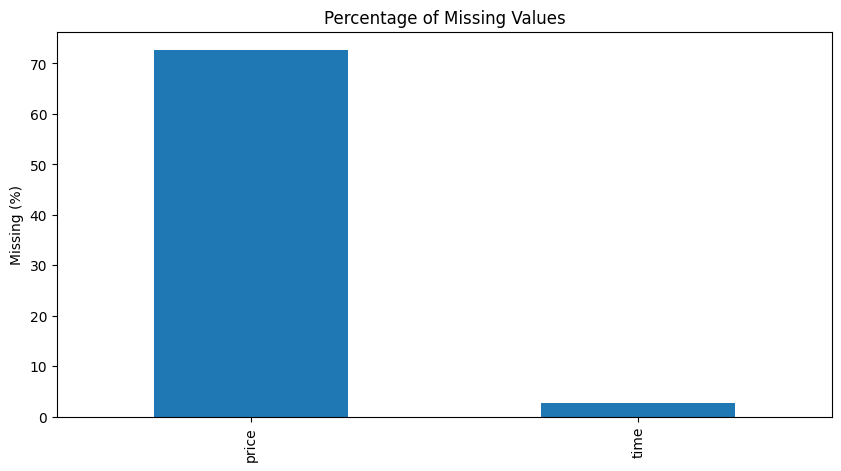

In [11]:
missing[missing > 0].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("Percentage of Missing Values")
plt.ylabel("Missing (%)")
plt.show()

# 5. Cleaning the Dates

In [13]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['date'].head()
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['decade'] = (df['year'] // 10) * 10

# 6. Creating KPI metrics

In [14]:
total_missions = len(df)

successful_missions = (
    df['mission_status'] == 'Success'
).sum()

success_rate = successful_missions / total_missions * 100

companies = df['company'].nunique()

print("Total missions:", total_missions)
print("Successful missions:", successful_missions)
print("Success rate:", round(success_rate, 2), "%")
print("Companies:", companies)

Total missions: 4630
Successful missions: 4162
Success rate: 89.89 %
Companies: 62


# 7. Analyzing Missions Over Time

In [15]:
missions_by_year = df.groupby('year').size().reset_index(name='missions')

fig = px.line(
    missions_by_year,
    x='year',
    y='missions',
    title='Space Missions by Year'
)

fig.show()

# 8. Analyzing Mission Success

In [16]:
mission_outcomes = (
    df['mission_status']
    .value_counts()
    .reset_index()
)

mission_outcomes.columns = ['mission_status', 'count']

mission_outcomes

,mission_status,count
0,Success,4162
1,Failure,357
2,Partial Failure,107
3,Prelaunch Failure,4


In [18]:
# Chart Form
fig = px.bar(
    mission_outcomes,
    x='mission_status',
    y='count',
    title='Mission Outcomes'
)

fig.show()

In [19]:
# Calculating Success Rate By Year
year_success = (
    df.assign(
        success=df['mission_status'].eq('Success')
    )
    .groupby('year')['success']
    .mean()
    .mul(100)
    .reset_index(name='success_rate')
)

In [20]:
# Visualizing These Results Above
fig = px.line(
    year_success,
    x='year',
    y='success_rate',
    title='Mission Success Rate Over Time',
    labels={'success_rate': 'Success Rate (%)'}
)

fig.show()

# 9. Analyzing Companies

In [22]:
top_companies = (
    df['company']
    .value_counts()
    .head(10)
    .reset_index()
)

top_companies.columns = ['company', 'missions']

fig = px.bar(
    top_companies.sort_values('missions'),
    x='missions',
    y='company',
    orientation='h',
    title='Top 10 Organizations by Number of Missions'
)

fig.show()

In [25]:
# Calculate Company Success Rates
company_stats = (
    df.groupby('company')
    .agg(
        missions=('mission_status', 'size'),
        successful=('mission_status', lambda x: (x == 'Success').sum())
    )
    .reset_index()
)

company_stats['success_rate'] = (
    company_stats['successful'] /
    company_stats['missions'] * 100
)

# Filters out companies with equal to or fewer than 20 missions
company_stats_filtered = company_stats[
    company_stats['missions'] >= 20
].sort_values(
    'success_rate',
    ascending=False
)

# Visualizing results
company_stats_filtered.head(10)

,company,missions,successful,success_rate
6,Blue Origin,21,21,100.000000
53,ULA,151,150,99.337748
24,ILS,46,45,97.826087
7,Boeing,136,131,96.323529
3,Arianespace,293,282,96.245734
33,Kosmotras,22,21,95.454545
37,MHI,87,83,95.402299
51,SpaceX,182,172,94.505495
9,CASC,338,318,94.082840
36,Lockheed,79,74,93.670886


# 10. Analyze Launch Locations

In [26]:
df['location'].value_counts().head(15)

locations = (
    df['location']
    .value_counts()
    .head(15)
    .sort_values()
)

fig = px.bar(
    locations,
    orientation='h',
    title='Top 15 Launch Locations'
)

fig.show()

# 11. Analyze Rocket Technology

In [27]:
df['rocket'].value_counts().head(15)

rocket_status_analysis = (
    df.groupby('rocket_status')['mission_status']
    .apply(lambda x: (x == 'Success').mean() * 100)
    .reset_index(name='success_rate')
)

rocket_status_analysis

,rocket_status,success_rate
0,Active,93.168317
1,Retired,88.977901


# 12. Analyze Missions Costs

In [28]:
df['price'] = (
    df['price']
    .astype(str)
    .str.replace(',', '')
)

df['price'] = pd.to_numeric(
    df['price'],
    errors='coerce'
)

df['price'].describe()

fig = px.histogram(
    df,
    x='price',
    nbins=50,
    title='Distribution of Mission Costs'
)

fig.show()

# 13. Building The Dashboard

In [29]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

In [32]:
dashboard = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=(
        "Missions by Year",
        "Success Rate Over Time",
        "Top Organizations",
        "Mission Outcomes",
        "Top Launch Locations",
        "Mission Cost Distribution"
    ),
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "domain"}],
        [{"type": "xy"}, {"type": "xy"}]
    ]
)

In [37]:
# Missions By Year
dashboard.add_trace(
    go.Scatter(
        x=missions_by_year['year'],
        y=missions_by_year['missions'],
        mode='lines+markers',
        name='Missions'
    ),
    row=1,
    col=1
)

# Success Rate
dashboard.add_trace(
    go.Scatter(
        x=year_success['year'],
        y=year_success['success_rate'],
        mode='lines+markers',
        name='Success Rate'
    ),
    row=1,
    col=2
)

# Organizations
dashboard.add_trace(
    go.Bar(
        x=top_companies.values,
        y=top_companies.index,
        orientation='h',
        name='Organizations'
    ),
    row=2,
    col=1
)

# Mission Outcomes
dashboard.add_trace(
    go.Pie(
        labels=mission_outcomes['mission_status'],
        values=mission_outcomes['count'],
        hole=0.4,
        name='Mission Outcomes'
    ),
    row=2,
    col=2
)

# Launch Locations
dashboard.add_trace(
    go.Bar(
        x = locations.values,
        y = locations.index,
        orientation='h',
        name='Launch Locations'
    ),
    row=3,
    col=1
)

# Mission Costs
cost_data = df.dropna(subset=['price'])

dashboard.add_trace(
    go.Histogram(
        x=cost_data['price'],
        nbinsx=50,
        name='Mission Cost'
    ),
    row=3,
    col=2
)

In [39]:
# Complete Code
dashboard.update_layout(
    title={
        'text': ' Space Mission Analytics Dashboard',
        'x': 0.5,
        'xanchor': 'center'
    },
    height=1400,
    width=1200,
    showlegend=False,
    template='plotly_white'
)

dashboard.update_xaxes(
    title_text='Year',
    row=1,
    col=1
)

dashboard.update_yaxes(
    title_text='Missions',
    row=1,
    col=1
)

dashboard.update_xaxes(
    title_text='Year',
    row=1,
    col=2
)

dashboard.update_yaxes(
    title_text='Success Rate (%)',
    row=1,
    col=2
)

dashboard.update_xaxes(
    title_text='Missions',
    row=2,
    col=1
)

dashboard.update_xaxes(
    title_text='Missions',
    row=3,
    col=1
)

dashboard.update_xaxes(
    title_text='Mission Cost',
    row=3,
    col=2
)

dashboard.show()

In [41]:
kpi_html = f"""
<div style="display:flex; justify-content:space-around;
            margin-bottom:25px; text-align:center;">

    <div style="padding:20px; border:1px solid #ddd;
                border-radius:10px; width:22%;">
        <h3>Total Missions</h3>
        <h2>{total_missions:,}</h2>
    </div>

    <div style="padding:20px; border:1px solid #ddd;
                border-radius:10px; width:22%;">
        <h3>Success Rate</h3>
        <h2>{success_rate:.2f}%</h2>
    </div>

    <div style="padding:20px; border:1px solid #ddd;
                border-radius:10px; width:22%;">
        <h3>Organizations</h3>
        <h2>{organizations:,}</h2>
    </div>

    <div style="padding:20px; border:1px solid #ddd;
                border-radius:10px; width:22%;">
        <h3>Rocket Types</h3>
        <h2>{rockets:,}</h2>
    </div>

</div>
"""

display(HTML(kpi_html))

dashboard.show()

## Conclusion

This analysis of global space launch data from 1957 to 2022 revealed several key trends and factors associated with mission success:

*   **Growth in Missions:** The number of space missions has generally increased over time, indicating a growing and evolving space industry. There are notable periods of acceleration in mission frequency.
*   **Improving Success Rates:** Overall, the mission success rate is high, hovering around 89.89%. While there have been fluctuations, particularly in the earlier decades, the industry has shown a consistent trend towards higher success rates, reflecting advancements in technology and operational expertise.
*   **Dominant Players:** A few key organizations, such as RVSN USSR (now Roscosmos), CASC, and Arianespace, have historically dominated the space launch landscape in terms of the sheer number of missions. However, new players like SpaceX are rapidly changing this dynamic.
*   **Location Matters:** Certain launch sites consistently host the most missions, likely due to their strategic geographical locations, established infrastructure, and favorable weather conditions.
*   **Price Variability:** Mission costs vary widely, and while the analysis showed a distribution, more detailed data would be needed to draw definitive conclusions about the impact of price on success or trends in cost-efficiency.
*   **Rocket Status:** Active rockets generally demonstrate a slightly higher success rate compared to retired rockets, which is expected given continuous technological improvements and maintenance for operational vehicles.

In summary, the global space launch industry has matured significantly, marked by a steady increase in activity and improving reliability. The continued involvement of established entities alongside the emergence of new, innovative companies points to a dynamic future for space exploration and utilization.